## 02b EDA cho RQ3 và RQ4

Notebook 02 đã trả lời RQ1, RQ2, RQ5. Notebook này làm nốt hai câu hỏi còn lại:

- RQ3. Những đặc điểm nào có mối liên hệ với thời gian chơi của người dùng Steam? Câu hỏi phụ: thể loại nào có thời gian chơi trung vị cao nhất, và xu hướng đó có giống nhau giữa toàn bộ lịch sử chơi và hai tuần gần nhất không?
- RQ4. Mức độ phổ biến và đánh giá của trò chơi thay đổi như thế nào theo thời gian phát hành? Câu hỏi phụ: các game phát hành ở những giai đoạn khác nhau có khác biệt về lượng người chơi và mức đánh giá không?

Đầu vào là `data/processed/games_cleaned.csv`.

### 2b.1. Đọc dữ liệu và tạo các cột dùng chung

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14

df = pd.read_csv("../data/processed/games_cleaned.csv", low_memory=False)

df["Release date"] = pd.to_datetime(df["Release date"])
df["Năm"] = df["Release date"].dt.year
df["Total reviews"] = df["Positive"] + df["Negative"]

# Tỷ lệ đánh giá tích cực, chỉ tính khi có từ 10 đánh giá (giống notebook 02)
df["Positive ratio"] = np.nan
du_danh_gia = df["Total reviews"] >= 10
df.loc[du_danh_gia, "Positive ratio"] = df.loc[du_danh_gia, "Positive"] / df.loc[du_danh_gia, "Total reviews"] * 100

# Nhóm giá giống notebook 02
nhom_gia = []
for gia in df["Price"]:
    if gia == 0:
        nhom_gia.append("Miễn phí")
    elif gia < 5:
        nhom_gia.append("Thấp (dưới 5 USD)")
    elif gia < 15:
        nhom_gia.append("Trung bình (5-15 USD)")
    else:
        nhom_gia.append("Cao (từ 15 USD)")
df["Nhóm giá"] = nhom_gia
thu_tu_gia = ["Miễn phí", "Thấp (dưới 5 USD)", "Trung bình (5-15 USD)", "Cao (từ 15 USD)"]

# 10 thể loại nội dung nhiều game nhất (bỏ Utilities, Design & Illustration vì là phần mềm)
ds_the_loai = ["Indie", "Casual", "Action", "Adventure", "Simulation", "Strategy",
               "RPG", "Sports", "Racing", "Massively Multiplayer"]

the_loai = df.dropna(subset=["Genres"]).copy()
the_loai["Genre"] = the_loai["Genres"].str.split(",")
the_loai = the_loai.explode("Genre")
the_loai["Genre"] = the_loai["Genre"].str.strip()
the_loai = the_loai[the_loai["Genre"].isin(ds_the_loai)]

print("Kích thước dữ liệu:", df.shape)

Kích thước dữ liệu: (125846, 25)


### 2b.2. RQ3: Phân phối thời gian chơi

Thời gian chơi tính bằng phút. Dùng Median playtime forever vì trung vị của một game ít bị ảnh hưởng bởi vài người chơi cực nhiều. Game có giá trị 0 là chưa ghi nhận được thời gian chơi nên chỉ xét game có giá trị lớn hơn 0.

Số game có thời gian chơi > 0: 26173
Tỷ lệ trên toàn bộ game: 20.8 %
Số game có thời gian chơi 2 tuần > 0: 3948
Trung vị (phút): 204.0
Tứ phân vị 25% và 75% (phút): 80.0 383.0
Lớn nhất (phút): 3429544


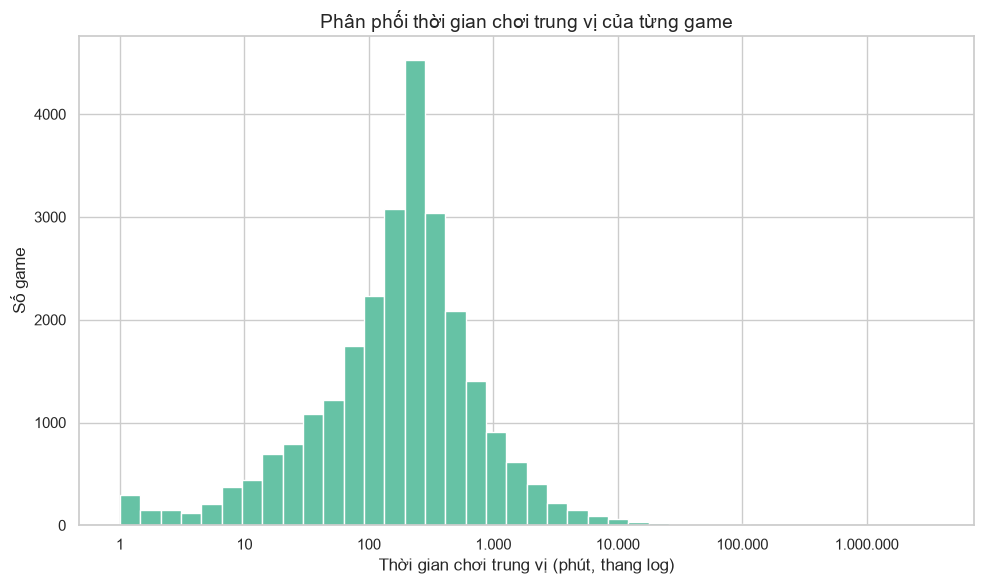

In [2]:
co_gio_choi = df[df["Median playtime forever"] > 0].copy()

print("Số game có thời gian chơi > 0:", len(co_gio_choi))
print("Tỷ lệ trên toàn bộ game:", round(len(co_gio_choi) / len(df) * 100, 1), "%")
print("Số game có thời gian chơi 2 tuần > 0:", (df["Median playtime two weeks"] > 0).sum())
print("Trung vị (phút):", co_gio_choi["Median playtime forever"].median())
print("Tứ phân vị 25% và 75% (phút):", co_gio_choi["Median playtime forever"].quantile(0.25),
      co_gio_choi["Median playtime forever"].quantile(0.75))
print("Lớn nhất (phút):", co_gio_choi["Median playtime forever"].max())

plt.figure()
plt.hist(np.log10(co_gio_choi["Median playtime forever"]), bins=40, edgecolor="white")
plt.xticks([0, 1, 2, 3, 4, 5, 6], ["1", "10", "100", "1.000", "10.000", "100.000", "1.000.000"])
plt.title("Phân phối thời gian chơi trung vị của từng game")
plt.xlabel("Thời gian chơi trung vị (phút, thang log)")
plt.ylabel("Số game")
plt.tight_layout()
plt.show()

Nhận xét:

- Chỉ 26.173 game (20,8%) có dữ liệu thời gian chơi, nên kết quả RQ3 nói về nhóm game này chứ không phải toàn bộ Steam.
- Trung vị là 204 phút, tức khoảng 3,4 giờ. Một nửa số game nằm trong khoảng 80 đến 383 phút.
- Giá trị lớn nhất là 3.429.544 phút, khoảng 6,5 năm. Giá trị này đáng nghi nên dùng trung vị thay cho trung bình.

### 2b.3. RQ3: Thời gian chơi theo thể loại

Phần này trả lời câu hỏi phụ của RQ3. Với mỗi thể loại, lấy trung vị thời gian chơi trên toàn bộ lịch sử và trên hai tuần gần nhất, sau đó so sánh thứ hạng giữa hai cột.

,Số game (toàn bộ),Trung vị toàn bộ (phút),Số game (2 tuần),Trung vị 2 tuần (phút),Hạng toàn bộ,Hạng 2 tuần
Thể loại,,,,,,
RPG,5958,266.0,1078,182.0,1,2
Strategy,5857,253.0,1015,149.0,2,3
Simulation,6500,224.0,1146,138.0,3,5
Adventure,10870,213.0,1567,143.0,4,4
Indie,17296,194.0,2043,104.0,5,8
Action,11059,189.0,1942,122.5,6,6
Casual,8692,187.0,964,106.0,7,7
Sports,1098,176.0,175,87.0,8,9
Massively Multiplayer,715,165.0,184,224.0,9,1


Tương quan thứ hạng giữa hai cột: 0.52


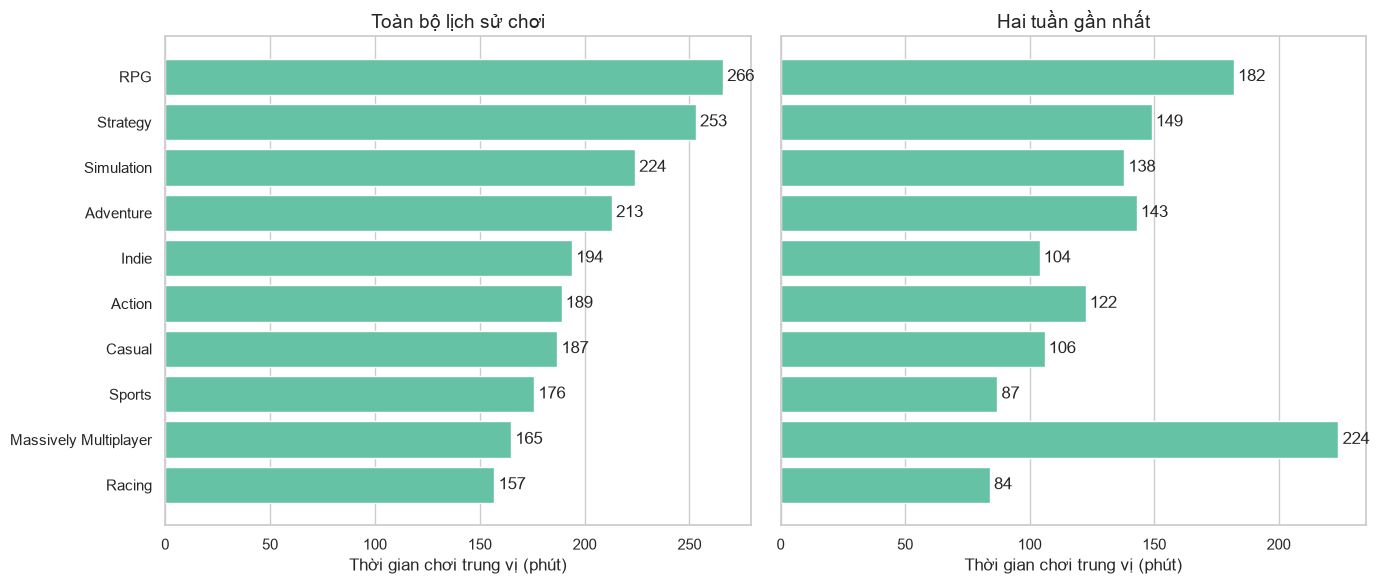

In [3]:
ket_qua = []
for ten in ds_the_loai:
    nhom = the_loai[the_loai["Genre"] == ten]
    toan_bo = nhom[nhom["Median playtime forever"] > 0]["Median playtime forever"]
    hai_tuan = nhom[nhom["Median playtime two weeks"] > 0]["Median playtime two weeks"]
    ket_qua.append({
        "Thể loại": ten,
        "Số game (toàn bộ)": len(toan_bo),
        "Trung vị toàn bộ (phút)": toan_bo.median(),
        "Số game (2 tuần)": len(hai_tuan),
        "Trung vị 2 tuần (phút)": hai_tuan.median(),
    })

bang_the_loai = pd.DataFrame(ket_qua).set_index("Thể loại")
bang_the_loai["Hạng toàn bộ"] = bang_the_loai["Trung vị toàn bộ (phút)"].rank(ascending=False).astype(int)
bang_the_loai["Hạng 2 tuần"] = bang_the_loai["Trung vị 2 tuần (phút)"].rank(ascending=False).astype(int)
bang_the_loai = bang_the_loai.sort_values("Trung vị toàn bộ (phút)", ascending=False)
display(bang_the_loai)

tuong_quan_hang = bang_the_loai["Trung vị toàn bộ (phút)"].corr(bang_the_loai["Trung vị 2 tuần (phút)"], method="spearman")
print("Tương quan thứ hạng giữa hai cột:", round(tuong_quan_hang, 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
mau = sns.color_palette()[0]
axes[0].barh(bang_the_loai.index, bang_the_loai["Trung vị toàn bộ (phút)"], color=mau)
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=3)
axes[0].set(title="Toàn bộ lịch sử chơi", xlabel="Thời gian chơi trung vị (phút)")
axes[0].invert_yaxis()
axes[1].barh(bang_the_loai.index, bang_the_loai["Trung vị 2 tuần (phút)"], color=mau)
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set(title="Hai tuần gần nhất", xlabel="Thời gian chơi trung vị (phút)")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Nhận xét:

- Trên toàn bộ lịch sử chơi, RPG cao nhất (266 phút), tiếp theo là Strategy (253 phút) và Simulation (224 phút). Racing thấp nhất (157 phút).
- Trong hai tuần gần nhất, Massively Multiplayer cao nhất (224 phút), trong khi xếp thứ 9 trên toàn bộ lịch sử. RPG và Strategy vẫn đứng thứ 2 và 3.
- Tương quan thứ hạng giữa hai cột là 0,52, nên xu hướng giống nhau một phần chứ không hoàn toàn.
- Cách hiểu hợp lý là game MMO thường được chơi đều đặn bởi những người còn chơi, còn RPG có thời lượng dài nhưng chơi xong thì dừng. Dữ liệu ở đây chưa chứng minh được cách hiểu này.
- Cột hai tuần chỉ có 3.948 game và chỉ gồm game vẫn còn người chơi, nên hai cột không so sánh trên cùng một nhóm game.

### 2b.4. RQ3: Thời gian chơi theo nhóm giá và tính năng

,Số game,Trung vị (phút)
Nhóm giá,,
Miễn phí,2608,92.0
Thấp (dưới 5 USD),13720,184.0
Trung bình (5-15 USD),7799,259.0
Cao (từ 15 USD),2046,470.5


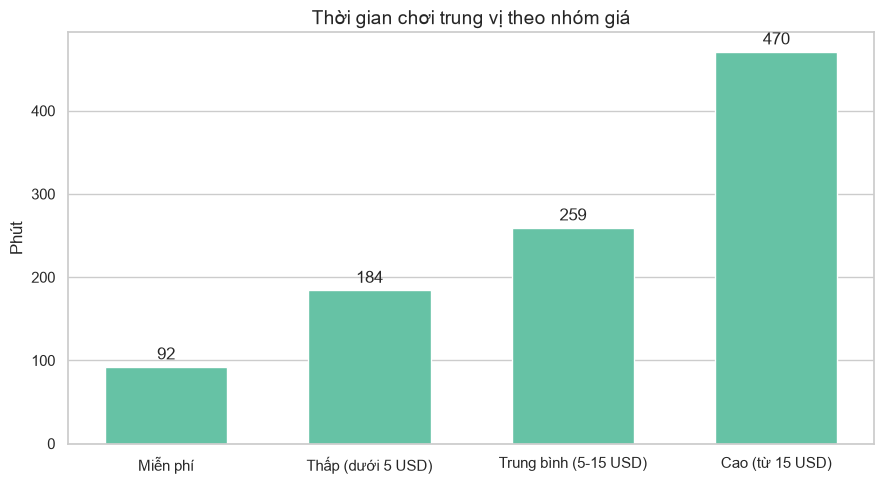

,Tính năng,Số game có,Trung vị khi có,Trung vị khi không có,Chênh lệch (phút)
4,Steam Cloud,12468,243.0,161.0,82.0
0,Single-player,24786,207.0,147.0,60.0
5,Full controller support,8488,217.0,196.0,21.0
2,Co-op,3916,214.5,202.0,12.5
3,Online PvP,2843,201.0,204.0,-3.0
1,Multi-player,6852,200.0,206.0,-6.0


In [4]:
gia = co_gio_choi.groupby("Nhóm giá")["Median playtime forever"].agg(["size", "median"]).reindex(thu_tu_gia)
gia.columns = ["Số game", "Trung vị (phút)"]
display(gia)

plt.figure(figsize=(9, 5))
ax = plt.gca()
ax.bar(gia.index, gia["Trung vị (phút)"], width=0.6)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set(title="Thời gian chơi trung vị theo nhóm giá", ylabel="Phút")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# So sánh game có và không có từng tính năng
ds_tinh_nang = ["Single-player", "Multi-player", "Co-op", "Online PvP", "Steam Cloud", "Full controller support"]
co_gio_choi["Danh sách tính năng"] = co_gio_choi["Categories"].fillna("").str.split(",")

ket_qua = []
for ten in ds_tinh_nang:
    co = []
    for ds in co_gio_choi["Danh sách tính năng"]:
        co.append(ten in ds)
    co = pd.Series(co, index=co_gio_choi.index)
    tv_co = co_gio_choi.loc[co, "Median playtime forever"].median()
    tv_khong = co_gio_choi.loc[~co, "Median playtime forever"].median()
    ket_qua.append({"Tính năng": ten, "Số game có": co.sum(), "Trung vị khi có": tv_co,
                    "Trung vị khi không có": tv_khong, "Chênh lệch (phút)": tv_co - tv_khong})

bang_tinh_nang = pd.DataFrame(ket_qua).sort_values("Chênh lệch (phút)", ascending=False)
display(bang_tinh_nang)

Nhận xét:

- Giá càng cao thì thời gian chơi càng dài: 92 phút ở nhóm miễn phí, 184 phút ở nhóm thấp, 259 phút ở nhóm trung bình và 470,5 phút ở nhóm cao.
- Steam Cloud có chênh lệch lớn nhất (+82 phút). Single-player cũng cao hơn (+60 phút), nhưng nhóm không có Single-player rất ít.
- Multi-player và Online PvP gần như không khác biệt (-6 và -3 phút).

### 2b.5. RQ3: Tương quan với các biến số

In [5]:
cac_bien = ["Price", "Achievements", "DLC count", "Peak CCU", "Total reviews",
            "Positive ratio", "Metacritic score", "Năm"]

ket_qua = []
for bien in cac_bien:
    cap = co_gio_choi[[bien, "Median playtime forever"]].dropna()
    ket_qua.append({"Biến": bien, "Số game": len(cap),
                    "Spearman": round(cap.corr(method="spearman").iloc[0, 1], 3)})

bang_tuong_quan = pd.DataFrame(ket_qua).sort_values("Spearman", ascending=False)
display(bang_tuong_quan)

,Biến,Số game,Spearman
3,Peak CCU,26173,0.346
0,Price,26173,0.283
4,Total reviews,26173,0.251
1,Achievements,26173,0.239
6,Metacritic score,3922,0.224
2,DLC count,26173,0.195
5,Positive ratio,23884,0.135
7,Năm,26173,0.125


Nhận xét:

- Thời gian chơi liên hệ cùng chiều với Peak CCU (0,346), giá (0,283), số đánh giá (0,251) và Achievements (0,239), nhưng đều ở mức yếu đến trung bình.
- Tỷ lệ tích cực (0,135) và năm phát hành (0,125) liên hệ rất yếu.

Trả lời RQ3: thời gian chơi liên hệ với thể loại và giá. RPG và Strategy có thời gian chơi cao nhất, game giá cao được chơi lâu hơn game rẻ. Xu hướng theo thể loại ở hai tuần gần nhất chỉ giống một phần với toàn bộ lịch sử, khác biệt rõ nhất là Massively Multiplayer. Kết quả chỉ là mối liên hệ và chỉ tính trên 20,8% game có dữ liệu.

### 2b.6. RQ4: Chất lượng dữ liệu theo năm phát hành

Trước khi so sánh theo năm cần xem dữ liệu của các năm có đầy đủ như nhau không. Notebook 01 (mục A3) đã cho thấy Estimated owners = "0 - 0" là thiếu dữ liệu, vì nhóm này có cả những game rất lớn. Vì vậy phần RQ4 bỏ nhóm này và bỏ năm 2026 (dữ liệu chỉ có vài tháng đầu năm).

Ngày phát hành của phần lớn game năm 2026 theo tháng:
Release date
1    1565
2    1706
3      42
6       1
9       1
Name: count, dtype: int64


,so_game,ty_le_owner_00
Năm,,
2014,1523,0.5
2015,2515,0.5
2016,4141,0.4
2017,5922,0.3
2018,7461,0.4
2019,7243,0.2
2020,8804,0.9
2021,11067,13.1
2022,12288,17.8


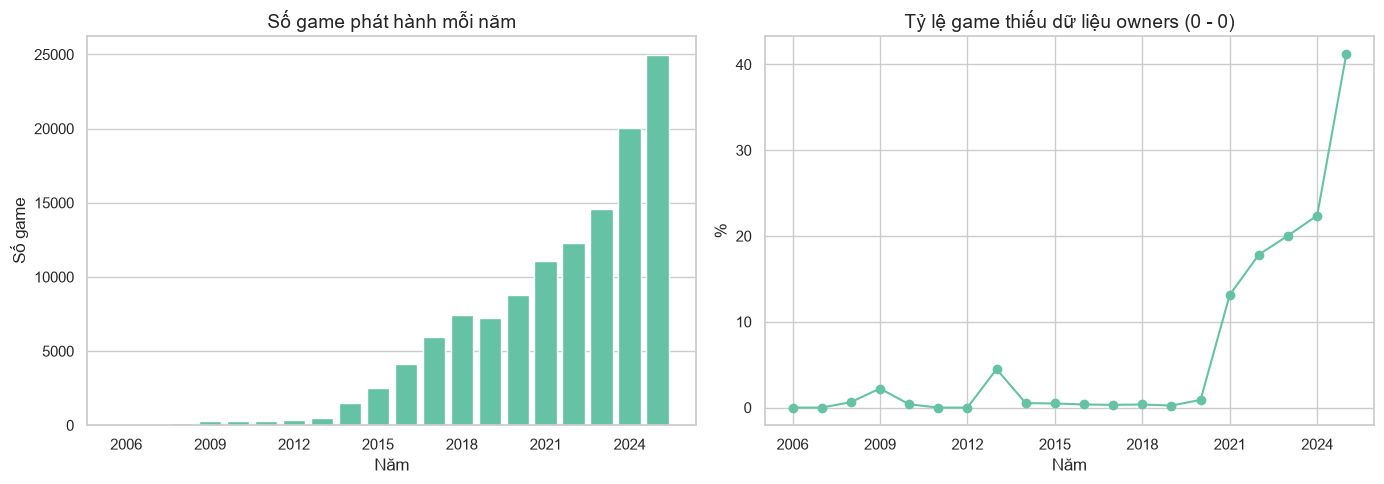

In [6]:
print("Ngày phát hành của phần lớn game năm 2026 theo tháng:")
print(df[df["Năm"] == 2026]["Release date"].dt.month.value_counts().sort_index())

theo_nam = df.groupby("Năm").agg(
    so_game=("id", "size"),
    ty_le_owner_00=("Estimated owners", lambda s: (s == "0 - 0").mean() * 100),
)
display(theo_nam.loc[2014:].round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
nam_ve = theo_nam.loc[2006:2025]
axes[0].bar(nam_ve.index, nam_ve["so_game"])
axes[0].set(title="Số game phát hành mỗi năm", xlabel="Năm", ylabel="Số game")
axes[0].grid(axis="x", visible=False)
axes[1].plot(nam_ve.index, nam_ve["ty_le_owner_00"], marker="o")
axes[1].set(title="Tỷ lệ game thiếu dữ liệu owners (0 - 0)", xlabel="Năm", ylabel="%")
for ax in axes:
    ax.set_xticks(range(2006, 2026, 3))
plt.tight_layout()
plt.show()

Nhận xét:

- Số game tăng rất nhanh, từ 1.523 game năm 2014 lên 24.973 game năm 2025.
- Dữ liệu 2026 gần như dừng ở tháng 3, nên có thể dữ liệu được thu thập vào khoảng thời gian đó.
- Tỷ lệ thiếu owners gần như bằng 0 đến năm 2020, sau đó tăng mạnh. So sánh các năm gần đây với năm cũ vì vậy kém chắc chắn hơn.

### 2b.7. RQ4: Mức độ phổ biến và đánh giá theo năm

Peak CCU là số người chơi cùng lúc cao nhất trong một ngày, không phải đỉnh trong lịch sử của game (xem `docs/data_dictionary.md`). Vì vậy "game có người chơi đồng thời" ở đây nghĩa là Peak CCU > 0, tức game còn người chơi vào ngày dữ liệu được ghi nhận. Peak CCU = 0 không có nghĩa game chưa từng có người chơi.

Số game dùng cho RQ4: 100974


,so_game,pct_co_ccu,reviews_trung_vi,so_game_du_danh_gia,tich_cuc_trung_vi,gia_trung_vi,pct_mien_phi,pct_du_danh_gia
Năm,,,,,,,,
2010,254,54.7,409.0,241,80.6,2.5,9.8,94.9
2011,260,56.2,836.0,258,77.4,2.5,10.8,99.2
2012,322,63.4,1110.0,321,80.5,3.0,11.5,99.7
2013,447,62.0,1197.0,444,79.1,2.5,10.5,99.3
2014,1515,44.4,318.0,1498,74.0,2.5,8.3,98.9
2015,2503,33.5,156.0,2408,73.5,2.5,11.2,96.2
2016,4126,27.3,88.0,3745,75.4,2.5,14.3,90.8
2017,5903,19.4,39.0,4654,75.0,2.1,15.3,78.8
2018,7434,15.9,27.0,5372,75.1,2.0,16.0,72.3


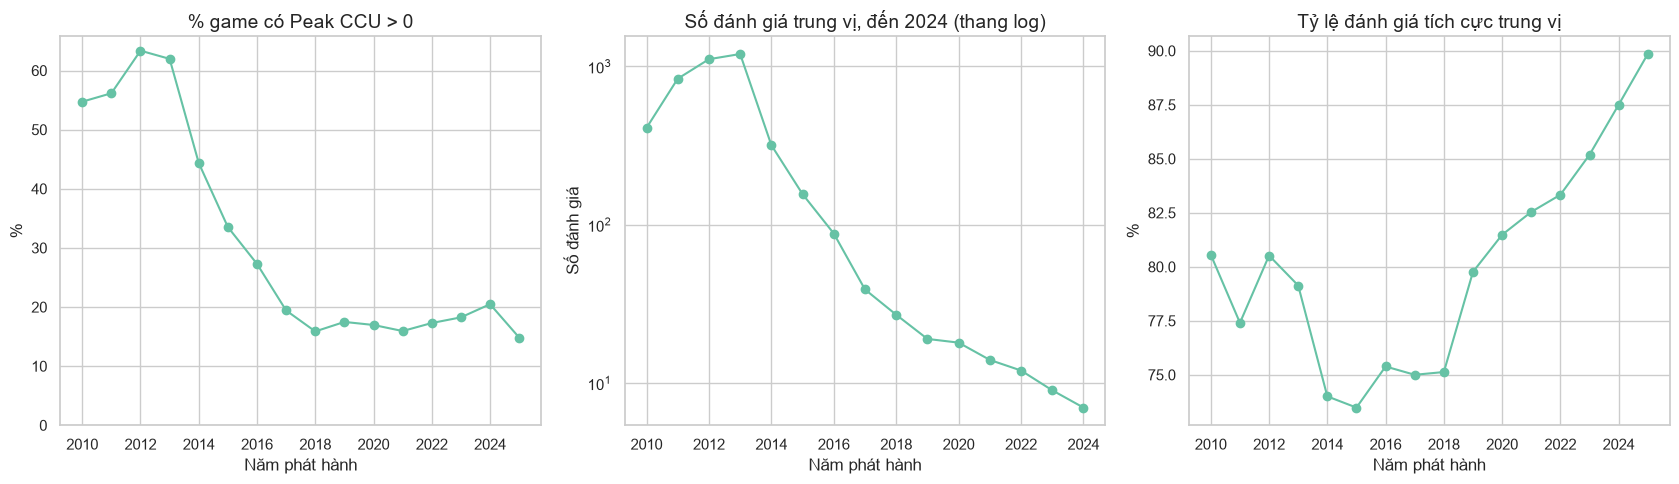

In [7]:
rq4 = df[(df["Estimated owners"] != "0 - 0") & (df["Năm"] <= 2025)].copy()
print("Số game dùng cho RQ4:", len(rq4))

theo_nam = rq4.groupby("Năm").agg(
    so_game=("id", "size"),
    pct_co_ccu=("Peak CCU", lambda s: (s > 0).mean() * 100),
    reviews_trung_vi=("Total reviews", "median"),
    so_game_du_danh_gia=("Positive ratio", "count"),
    tich_cuc_trung_vi=("Positive ratio", "median"),
    gia_trung_vi=("Price", "median"),
    pct_mien_phi=("Price", lambda s: (s == 0).mean() * 100),
)
theo_nam["pct_du_danh_gia"] = theo_nam["so_game_du_danh_gia"] / theo_nam["so_game"] * 100
display(theo_nam.loc[2010:].round(1))

nam_ve = theo_nam.loc[2010:2025]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(nam_ve.index, nam_ve["pct_co_ccu"], marker="o")
axes[0].set(title="% game có Peak CCU > 0", xlabel="Năm phát hành", ylabel="%", ylim=(0, None))
# Năm 2025 có trung vị bằng 0 nên không vẽ được trên thang log
den_2024 = nam_ve.loc[:2024]
axes[1].plot(den_2024.index, den_2024["reviews_trung_vi"], marker="o")
axes[1].set(title="Số đánh giá trung vị, đến 2024 (thang log)", xlabel="Năm phát hành", ylabel="Số đánh giá")
axes[1].set_yscale("log")
axes[2].plot(nam_ve.index, nam_ve["tich_cuc_trung_vi"], marker="o")
axes[2].set(title="Tỷ lệ đánh giá tích cực trung vị", xlabel="Năm phát hành", ylabel="%")
plt.tight_layout()
plt.show()

Nhận xét:

- Tỷ lệ game có Peak CCU > 0 giảm từ khoảng 62% ở năm 2012-2013 xuống 15,9% ở năm 2018, sau đó ổn định quanh 16-20% đến năm 2024.
- Số đánh giá trung vị giảm từ 1.197 (2013) xuống 7 (2024). Một phần là vì game cũ có nhiều thời gian tích lũy đánh giá hơn.
- Tỷ lệ tích cực thấp nhất ở năm 2015 (73,5%) rồi tăng dần lên 89,8% ở năm 2025. Tuy nhiên tỷ lệ game đủ 10 đánh giá cũng giảm từ 96,2% xuống 21,5%, tức năm càng mới thì càng chỉ còn những game khá nổi mới được tính.
- Tỷ lệ game miễn phí giảm từ 16,3% (2020) xuống 8,8% (2021). Đây không phải thay đổi thật mà do game miễn phí từ 2021 thiếu dữ liệu owners.

### 2b.8. RQ4: So sánh giữa các giai đoạn phát hành

Phần này trả lời câu hỏi phụ của RQ4. Chia năm phát hành thành 5 giai đoạn.

,so_game,pct_co_ccu,reviews_trung_vi,tich_cuc_trung_vi,so_game_du_danh_gia,pct_du_danh_gia
Giai đoạn,,,,,,
Trước 2014,1935,62.3,810.0,80.8,1890,97.7
2014-2017,14047,26.9,84.0,75.0,12305,87.6
2018-2020,23385,16.8,21.0,78.9,15659,67.0
2021-2023,31379,17.2,11.0,83.6,16763,53.4
2024-2025,30228,17.7,2.0,88.2,10045,33.2


Chỉ xét game có từ 100 đánh giá:


,so_game,tich_cuc_trung_vi,pct_co_ccu
Giai đoạn,,,
Trước 2014,1666,81.9,69.0
2014-2017,6546,78.6,50.4
2018-2020,5667,83.4,53.4
2021-2023,5543,84.7,65.9
2024-2025,3382,86.5,80.5


Giai đoạn,Trước 2014,2014-2017,2018-2020,2021-2023,2024-2025
Genre,,,,,
Action,81.9,74.5,77.1,82.5,87.4
Adventure,83.1,75.0,78.8,82.8,87.5
Casual,80.5,75.0,79.5,85.2,90.0
Indie,80.6,75.0,79.4,84.3,89.1
Simulation,75.3,71.0,74.2,78.6,84.0
Strategy,78.5,72.7,75.6,81.2,86.6


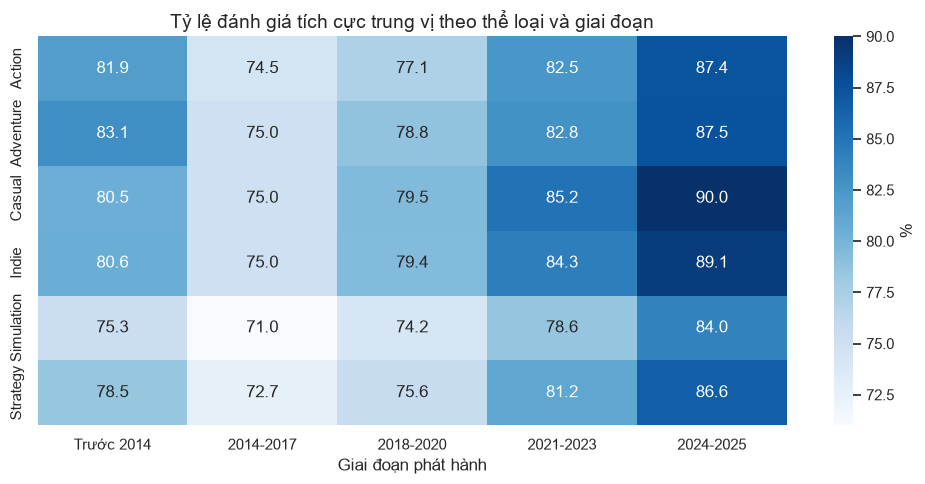

In [8]:
giai_doan = []
for nam in rq4["Năm"]:
    if nam < 2014:
        giai_doan.append("Trước 2014")
    elif nam <= 2017:
        giai_doan.append("2014-2017")
    elif nam <= 2020:
        giai_doan.append("2018-2020")
    elif nam <= 2023:
        giai_doan.append("2021-2023")
    else:
        giai_doan.append("2024-2025")
rq4["Giai đoạn"] = giai_doan
thu_tu_gd = ["Trước 2014", "2014-2017", "2018-2020", "2021-2023", "2024-2025"]

bang_gd = rq4.groupby("Giai đoạn").agg(
    so_game=("id", "size"),
    pct_co_ccu=("Peak CCU", lambda s: (s > 0).mean() * 100),
    reviews_trung_vi=("Total reviews", "median"),
    tich_cuc_trung_vi=("Positive ratio", "median"),
    so_game_du_danh_gia=("Positive ratio", "count"),
).reindex(thu_tu_gd)
bang_gd["pct_du_danh_gia"] = bang_gd["so_game_du_danh_gia"] / bang_gd["so_game"] * 100
display(bang_gd.round(1))

# Kiểm tra lại trên nhóm game đã khá nổi tiếng (từ 100 đánh giá) để giảm ảnh hưởng của việc
# game mới có ít thời gian tích lũy đánh giá
nhom_100 = rq4[rq4["Total reviews"] >= 100]
bang_100 = nhom_100.groupby("Giai đoạn").agg(
    so_game=("id", "size"),
    tich_cuc_trung_vi=("Positive ratio", "median"),
    pct_co_ccu=("Peak CCU", lambda s: (s > 0).mean() * 100),
).reindex(thu_tu_gd)
print("Chỉ xét game có từ 100 đánh giá:")
display(bang_100.round(1))

# Xu hướng trong từng thể loại lớn
the_loai_rq4 = the_loai[(the_loai["Estimated owners"] != "0 - 0") & (the_loai["Năm"] <= 2025)].copy()
the_loai_rq4 = the_loai_rq4.merge(rq4[["id", "Giai đoạn"]], on="id")
top6 = ["Indie", "Casual", "Action", "Adventure", "Simulation", "Strategy"]
bang_tl = the_loai_rq4[the_loai_rq4["Genre"].isin(top6)].pivot_table(
    index="Genre", columns="Giai đoạn", values="Positive ratio", aggfunc="median")[thu_tu_gd]

display(bang_tl.round(1))

plt.figure(figsize=(10, 5))
sns.heatmap(bang_tl, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "%"})
plt.title("Tỷ lệ đánh giá tích cực trung vị theo thể loại và giai đoạn")
plt.xlabel("Giai đoạn phát hành")
plt.ylabel("")
plt.tight_layout()
plt.show()

Nhận xét:

- Giai đoạn trước 2014 có 62,3% game có người chơi đồng thời, cao hơn hẳn các giai đoạn sau (16,8-26,9%). Giai đoạn này chỉ có 1.935 game. Peak CCU chỉ đo trong một ngày, nên con số này cho thấy nhiều game cũ sau hơn 10 năm vẫn còn người chơi.
- Từ 2018 trở đi tỷ lệ gần như không đổi (16,8%, 17,2%, 17,7%).
- Tỷ lệ tích cực trung vị thấp nhất ở 2014-2017 (75,0%) và cao nhất ở 2024-2025 (88,2%).
- Khi chỉ xét game có từ 100 đánh giá, xu hướng tăng vẫn còn nhưng nhỏ hơn: từ 78,6% lên 86,5%. Một phần xu hướng là do cách chọn game, không phải toàn bộ.
- Xu hướng này giống nhau ở cả 6 thể loại lớn: thấp nhất ở 2014-2017 và cao nhất ở 2024-2025.

Trả lời RQ4: game phát hành sớm có tỷ lệ còn người chơi và số đánh giá cao hơn rõ rệt, còn từ 2018 tỷ lệ game có Peak CCU > 0 gần như không đổi. Tỷ lệ tích cực giảm đến 2014-2017 rồi tăng lại. Tuy nhiên game cũ có nhiều thời gian tích lũy hơn, game cũ còn tồn tại thường là game tốt, và dữ liệu các năm gần đây thiếu nhiều, nên không thể kết luận game ngày nay thật sự được yêu thích hơn hay kém phổ biến hơn.

#### Lưu bảng kết quả

In [9]:
# Lưu các bảng chính để dùng trong báo cáo
bang_the_loai.to_csv("../reports/tables/rq3_thoi_gian_choi_theo_the_loai.csv", encoding="utf-8-sig")
bang_gd.to_csv("../reports/tables/rq4_theo_giai_doan.csv", encoding="utf-8-sig")
print("Đã lưu bảng vào reports/tables")

Đã lưu bảng vào reports/tables
